In [1]:
import pandas as pd

players = pd.read_csv("../data/raw/players.csv")
valuations = pd.read_csv("../data/raw/player_valuations.csv")

print("players:", players.shape)
print("valuations:", valuations.shape)
print()
print("players columns:", players.columns.tolist())
print()
print("valuations columns:", valuations.columns.tolist())

players: (50149, 26)
valuations: (656301, 6)

players columns: ['player_id', 'first_name', 'last_name', 'name', 'last_season', 'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth', 'country_of_citizenship', 'date_of_birth', 'sub_position', 'position', 'foot', 'height_in_cm', 'contract_expiration_date', 'agent_name', 'image_url', 'international_caps', 'international_goals', 'current_national_team_id', 'url', 'current_club_domestic_competition_id', 'current_club_name', 'market_value_in_eur', 'highest_market_value_in_eur']

valuations columns: ['player_id', 'date', 'market_value_in_eur', 'current_club_name', 'current_club_id', 'player_club_domestic_competition_id']


In [2]:
players.head()

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,...,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,1000000.0,30000000.0
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,...,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,750000.0,8000000.0
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,...,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,1000000.0,34500000.0
3,77,NaN,Lúcio,Lúcio,2012,506,lucio,Brazil,Brasília,Brazil,...,NaN,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/lucio/profil/s...,IT1,Juventus FC,200000.0,24500000.0
4,80,Tom,Starke,Tom Starke,2017,27,tom-starke,East Germany (GDR),Freital,Germany,...,IFM,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/tom-starke/pro...,L1,Bayern Munich,100000.0,3000000.0


In [3]:
valuations.head()

,player_id,date,market_value_in_eur,current_club_name,current_club_id,player_club_domestic_competition_id
0,405973,2000-01-20,150000,Unknown,3057,BE1
1,342216,2001-07-20,100000,Unknown,1241,SC1
2,3132,2003-12-09,400000,Dynamo Kyiv,126,TR1
3,6893,2003-12-15,900000,Galatasaray,984,GB1
4,10,2004-10-04,7000000,SV Werder Bremen,398,IT1


In [4]:
players["date_of_birth"] = pd.to_datetime(players["date_of_birth"])
players["contract_expiration_date"] = pd.to_datetime(players["contract_expiration_date"])
valuations["date"] = pd.to_datetime(valuations["date"])

print(players.isna().mean().round(3).sort_values(ascending=False).head(12))
print()
print(valuations.isna().sum())
print()
print(valuations["market_value_in_eur"].describe())
print("Date range:", valuations["date"].min(), "to", valuations["date"].max())

current_national_team_id       0.935
international_caps             0.614
international_goals            0.614
agent_name                     0.465
contract_expiration_date       0.370
highest_market_value_in_eur    0.172
market_value_in_eur            0.172
foot                           0.118
country_of_birth               0.117
city_of_birth                  0.112
height_in_cm                   0.087
first_name                     0.063
dtype: float64

player_id                                  0
date                                       0
market_value_in_eur                        0
current_club_name                          0
current_club_id                            0
player_club_domestic_competition_id    92973
dtype: int64

count    6.563010e+05
mean     2.290093e+06
std      6.721809e+06
min      0.000000e+00
25%      2.000000e+05
50%      5.000000e+05
75%      1.500000e+06
max      2.000000e+08
Name: market_value_in_eur, dtype: float64
Date range: 2000-01-20 00:00:00 to 202

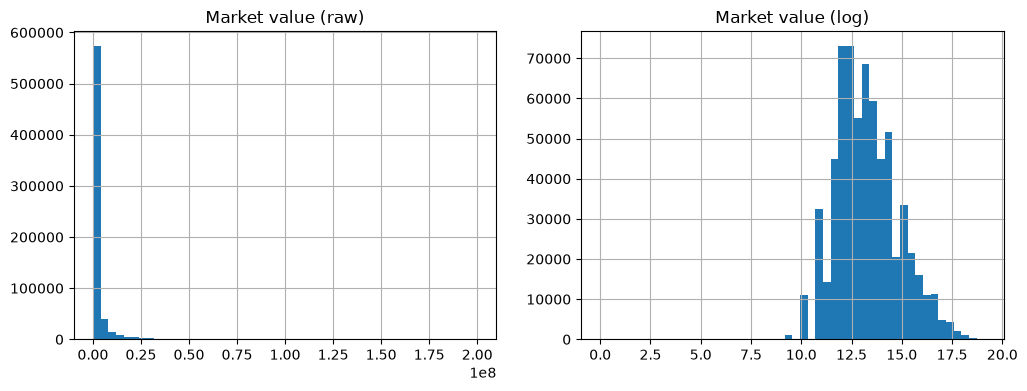

In [5]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
valuations["market_value_in_eur"].hist(bins=50, ax=ax[0])
ax[0].set_title("Market value (raw)")
np.log1p(valuations["market_value_in_eur"]).hist(bins=50, ax=ax[1])
ax[1].set_title("Market value (log)")
plt.show()

In [6]:
player_cols = [
    "player_id", "date_of_birth", "position", "sub_position", "foot",
    "height_in_cm", "country_of_citizenship",
]

df = valuations.merge(players[player_cols], on="player_id", how="left")

# Age at the time of valuation
df["age"] = (df["date"] - df["date_of_birth"]).dt.days / 365.25

# Remove unusable rows
df = df.dropna(subset=["market_value_in_eur", "date_of_birth"])
df = df[df["market_value_in_eur"] > 0]

print(df.shape)
df.head()

(655700, 13)


,player_id,date,market_value_in_eur,current_club_name,current_club_id,player_club_domestic_competition_id,date_of_birth,position,sub_position,foot,height_in_cm,country_of_citizenship,age
0,405973,2000-01-20,150000,Unknown,3057,BE1,1998-01-16,Attack,Left Winger,NaN,181.0,Togo,2.009582
1,342216,2001-07-20,100000,Unknown,1241,SC1,1998-02-13,Defender,Left-Back,left,181.0,France,3.430527
2,3132,2003-12-09,400000,Dynamo Kyiv,126,TR1,1980-03-10,Midfield,Attacking Midfield,left,168.0,Romania,23.748118
3,6893,2003-12-15,900000,Galatasaray,984,GB1,1983-11-09,Defender,Centre-Back,right,188.0,Romania,20.098563
4,10,2004-10-04,7000000,SV Werder Bremen,398,IT1,1978-06-09,Attack,Centre-Forward,right,184.0,Germany,26.321697


In [7]:
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/base.csv", index=False)

In [8]:
df["year"] = df["date"].dt.year
print(df["year"].value_counts().sort_index())
print()
print(df["age"].describe())
print("Age < 15:", (df["age"] < 15).sum(), "| Age > 42:", (df["age"] > 42).sum())

year
2000        1
2001        1
2003        2
2004     2296
2005     2426
2006     2653
2007     5604
2008     9278
2009    12031
2010    13760
2011    17741
2012    19665
2013    22589
2014    23668
2015    30431
2016    34610
2017    35882
2018    41059
2019    46058
2020    48734
2021    58385
2022    59552
2023    57568
2024    45373
2025    45481
2026    20852
Name: count, dtype: int64

count    655700.000000
mean         25.254155
std           4.569777
min           2.009582
25%          21.642710
50%          24.698152
75%          28.372348
max          45.650924
Name: age, dtype: float64
Age < 15: 12 | Age > 42: 82


In [9]:
START_YEAR = 2012  # adjust based on the year counts

df = df[(df["age"] >= 15) & (df["age"] <= 42)]
df = df[df["year"] >= START_YEAR]

df["player_club_domestic_competition_id"] = (
    df["player_club_domestic_competition_id"].fillna("UNK")
)
df = df.reset_index(drop=True)

print(df.shape)
df.to_csv("../data/processed/base.csv", index=False)

(589824, 14)


In [10]:
appearances = pd.read_csv("../data/raw/appearances.csv")
clubs = pd.read_csv("../data/raw/clubs.csv")

print("appearances:", appearances.shape)
print(appearances.columns.tolist())
print()
print("clubs:", clubs.shape)
print(clubs.columns.tolist())

appearances: (1894350, 13)
['appearance_id', 'game_id', 'player_id', 'player_club_id', 'player_current_club_id', 'date', 'player_name', 'competition_id', 'yellow_cards', 'red_cards', 'goals', 'assists', 'minutes_played']

clubs: (796, 17)
['club_id', 'club_code', 'name', 'domestic_competition_id', 'total_market_value', 'squad_size', 'average_age', 'foreigners_number', 'foreigners_percentage', 'national_team_players', 'stadium_name', 'stadium_seats', 'net_transfer_record', 'coach_name', 'last_season', 'filename', 'url']


In [11]:
appearances["date"] = pd.to_datetime(appearances["date"])
print("Appearances date range:", appearances["date"].min(), "to", appearances["date"].max())
print()
print(appearances["date"].dt.year.value_counts().sort_index())


Appearances date range: 2012-07-03 00:00:00 to 2026-06-28 00:00:00

date
2012     71688
2013    129862
2014    125776
2015    132338
2016    131075
2017    135103
2018    126996
2019    128672
2020    114160
2021    147383
2022    129335
2023    150698
2024    145640
2025    153216
2026     72408
Name: count, dtype: int64
